<a href="https://colab.research.google.com/github/kangyeson/AI-Class/blob/main/1109/stock_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
pip install finance-datareader

In [3]:
# !pip install finance-datareader
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
samsung = fdr.DataReader('005930', '2016')
print(samsung)

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195400  187000  194700  10416508  0.006202

[2660 rows x 6 columns]


In [5]:
openValues = samsung[['Open']]

In [6]:
openValues

,Open
Date,
2016-01-04,25200
2016-01-05,24040
2016-01-06,24160
2016-01-07,23320
2016-01-08,23260
...,...
2026-11-03,220500
2026-11-04,226500
2026-11-05,213000


In [7]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
scaled = scaler.fit_transform(openValues)
scaled

array([[0.06765101],
       [0.06453691],
       [0.06485906],
       ...,
       [0.57181208],
       [0.48322148],
       [0.50255034]], shape=(2660, 1))

In [8]:
TEST_SIZE=200
train_data=scaled[:-TEST_SIZE]
test_data=scaled[-TEST_SIZE:]

In [9]:
def make_sample(data, window):
    train = []
    target = []
    for i in range(len(data)-window):
      train.append(data[i:i+window])
      target.append(data[i+window])
    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 30)

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import SimpleRNN

model = Sequential()
model.add(SimpleRNN(16,
                    input_shape=(X_train.shape[1], 1),
                    activation='tanh',
                    return_sequences=False)
)
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)

Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0027
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2.2220e-04
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.7433e-04
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.4424e-04
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 1.2036e-04
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 1.3102e-04
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.0372e-04
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.0545e-04
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 9.4322e-05
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.0897e-04
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 8.2001e-05
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 8.6397e-05
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 7.2842e-05
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 7.

In [12]:
X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


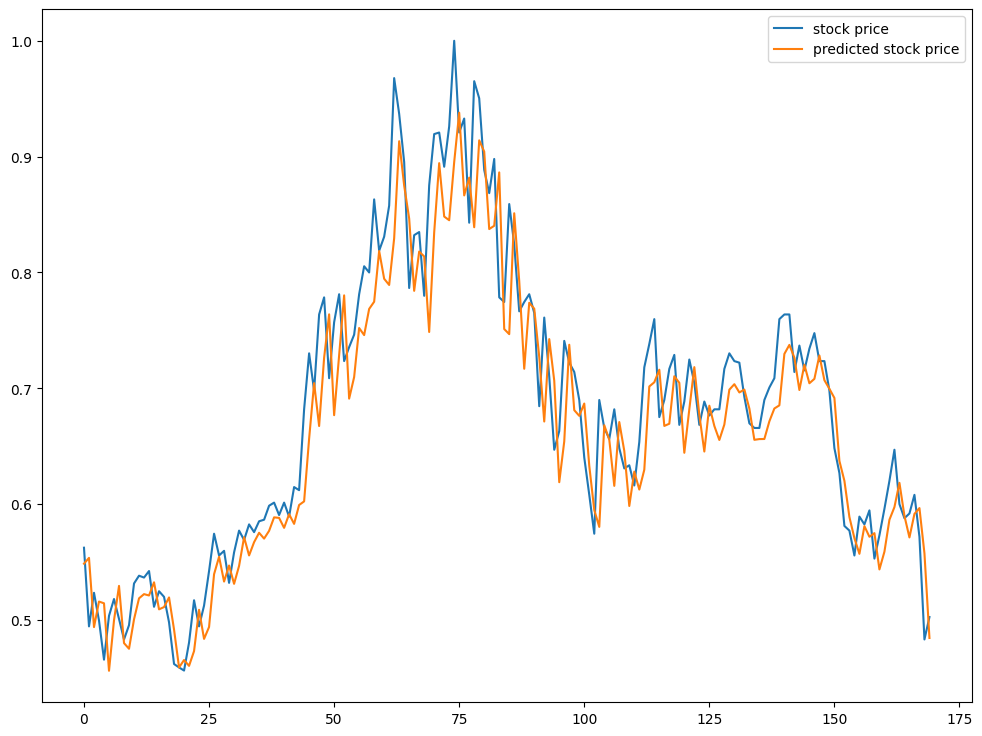

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()